In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:41551")
client

<Client: 'tcp://127.0.0.1:41551' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
for pp in range(6,9):
    if pp == 6:
        ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).chunk({"time":4,"level":1,"y":128,"x":256})
    else:
        tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(time=slice(1,None),
                                   # level=slice(1,None)
                                  ).chunk({"time":4,"level":1,"y":128,"x":256}
                                         )
        time = tmp.time.data + ds.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time", time)
        ds = xr.concat([ds, tmp], "time")
        tmp.close()
    
ds

<xarray.Dataset> Size: 317GB
Dimensions:  (time: 630, level: 5, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>

[2.13 3.85 5.26 6.27] <xarray.DataArray (lp1: 4)> Size: 32B
array([1002.13, 1001.72, 1001.41, 1001.01])
Coordinates:
  * lp1      (lp1) float64 32B 0.5 1.5 2.5 3.5
Fitted Equation: y = 0.0118 * e^(0.2000 * x) + -0.0334


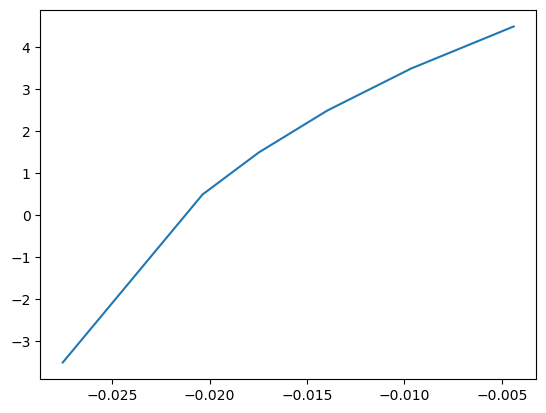

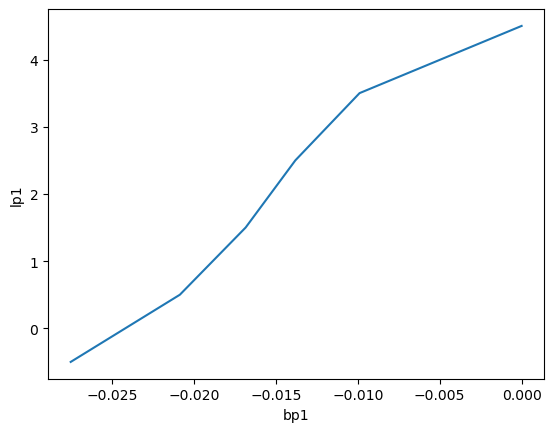

(<xarray.Dataset> Size: 550GB
 Dimensions:  (time: 630, level: 5, y: 2048, x: 4096, lp1: 6, yG: 2047, xG: 4095)
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
   * yG       (yG) float32 8kB 9.021 9.041 9.062 9.082 ... 50.94 50.96 50.98
   * xG       (xG) float32 16kB -97.98 -97.96 -97.94 ... -14.06 -14.04 -14.02
 Data variables:
     h        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     Z        (time, level, y, x) float32

In [5]:
rho0 = 1e3
drho = np.array([2.13, 1.72, 1.41, 1.01,])
rho = xr.DataArray(drho + rho0, 
                   dims="lp1",
                   coords={"lp1":np.array([0.5,1.5,2.5,3.5,])}
                  )
print(np.cumsum(drho), rho)

# log_y = np.log(rho)

# # 2. Fit a 1st-degree polynomial (linear fit: y = mx + c)
# # Returns [B, ln(A)]
# coefficients = np.polyfit(rho.lp1.data, log_y, 1)

# # 3. Extract the parameters
# B = coefficients[0]
# A = np.exp(coefficients[1])

# print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x)")

# rp1 = np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5)),]),rho.data)),
#                     np.array([A*np.exp(B*(4.5)),]) 
#                    ))

g = 9.8
b = -g*(rho - rho0) / rho0

B = 0.2
def exp_func(x, a, c):
    return a * np.exp(B * x) + c

initial_guess = [1, -1e-2]
popt, pcov = curve_fit(exp_func, b.lp1.values, b.values, p0=initial_guess)

# 3. Extract parameters
A, C = popt
print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x) + {C:.4f}")
plt.plot(A*np.exp(B*np.array([-3.5,0.5,1.5,2.5,3.5,4.5]))+C, 
         np.array([-3.5,0.5,1.5,2.5,3.5,4.5]))
plt.show()

# bp1 = xr.DataArray(np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5))+C,]),b.data)),
#                     np.array([A*np.exp(B*(4.5))+C,]) 
#                    )), dims="lp1", 
#                    coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
#                   )
bp1 = xr.DataArray(np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5))+C,]),b.data)),
                    np.array([0.,]) 
                   )), dims="lp1", 
                   coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                  )

ds2 = ds.copy()

ssh = xr.open_zarr(op.join(ddir,"SW/48/SSH.zarr")).ssh
# dszl = xr.open_zarr(op.join(ddir,"SW/48/Zl.zarr"))
# dsz = xr.open_zarr(op.join(ddir,"SW/48/Z.zarr"))
dsz = xr.open_zarr(op.join(ddir,"SW/48/Z.zarr")
                  ).Z.transpose("time","level","y","x"
                               ).to_dataset(name="Z")
dsz["Zl"] = xr.open_zarr(op.join(ddir,"SW/48/Zl.zarr")
                        ).Zl.transpose("time","lp1","y","x")
ds2["Z"] = dsz.Z.transpose("time","level","y","x").chunk({"level":-1})
Zp1 = xr.concat([dsz.Zl, xr.DataArray(ssh.data[:,np.newaxis,:,:],
                                    dims=dsz.Zl.dims, 
                                    coords={"lp1":np.array([4.5,])})
                ], "lp1")
ds2["Zp1"] = Zp1.transpose("time","lp1","y","x").chunk({"lp1":-1})
ds2["bp1"] = bp1
ds2.bp1.plot(y="lp1")
plt.show()

llo, lla = np.meshgrid(ds.x, ds.y)
xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
                  coords={"y":ds.y.data,
                          "xG":.5*(ds.x.data[1:]+ds.x.data[:-1])}
                 )
yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
                  coords={"yG":.5*(ds.y.data[1:]+ds.y.data[:-1]),
                          "x":ds.x.data}
                 )
ds2.coords["yG"] = ("yG",.5*(ds.y.data[1:]+ds.y.data[:-1]))
ds2.coords["xG"] = ("xG",.5*(ds.x.data[1:]+ds.x.data[:-1]))

grid = Grid(ds2, 
            padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
            autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1"}
                   })

ds2, grid

In [6]:
# dsz = xr.open_zarr(op.join(ddir,"SW/48/Z.zarr")
#                   ).Z.transpose("time","level","y","x"
#                                ).to_dataset(name="Z")
# dsz["Zl"] = xr.open_zarr(op.join(ddir,"SW/48/Zl.zarr")
#                         ).Zl.transpose("time","lp1","y","x")
dsz.coords["yG"] = ("yG",.5*(ds2.y.data[1:]+ds2.y.data[:-1]))
dsz.coords["xG"] = ("xG",.5*(ds2.x.data[1:]+ds2.x.data[:-1]))
dsz.coords["li"] = ("li",ds2.lp1.isel(lp1=slice(1,-1)).data)

gridz = Grid(dsz, 
             # periodic=None,
             padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
             autoparse_metadata=False,
             coords={"X": {"center": "x", "inner": "xG"},
                     "Y": {"center": "y", "inner": "yG"},
                     "Z": {"center": "level", "left": "lp1", "inner": "li"}
                    })
dsz, gridz

(<xarray.Dataset> Size: 211GB
 Dimensions:  (level: 5, time: 630, x: 4096, y: 2048, lp1: 5, yG: 2047,
               xG: 4095, li: 4)
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * lp1      (lp1) float64 40B -0.5 0.5 1.5 2.5 3.5
   * yG       (yG) float32 8kB 9.021 9.041 9.062 9.082 ... 50.94 50.96 50.98
   * xG       (xG) float32 16kB -97.98 -97.96 -97.94 ... -14.06 -14.04 -14.02
   * li       (li) float64 32B 0.5 1.5 2.5 3.5
 Data variables:
     Z        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 4, 128, 256), meta=np.ndarray>
     Zl       (time, lp1, y, x) float32 106GB dask.array<chunksize=(4, 5, 128, 256), meta=np.ndarray>,
 <xgcm.Grid>
 X Axis (not periodic, padding='extend'):
   * center   x --> inner


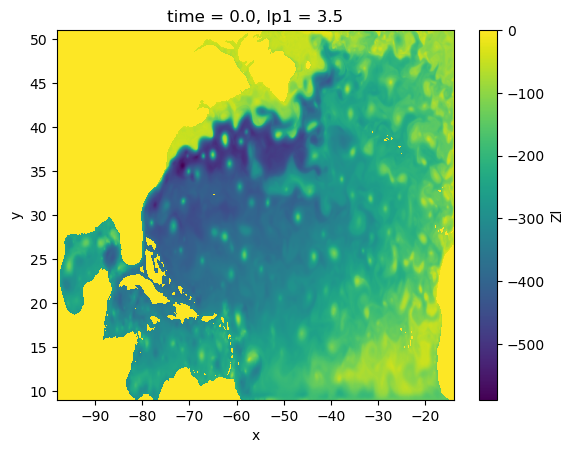

In [17]:
dsz.Zl.isel(time=0,lp1=-1).plot(rasterized=True)

[4.018e-03 3.038e-03 3.920e-03 9.898e-03 1.000e+01]


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 27.15 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


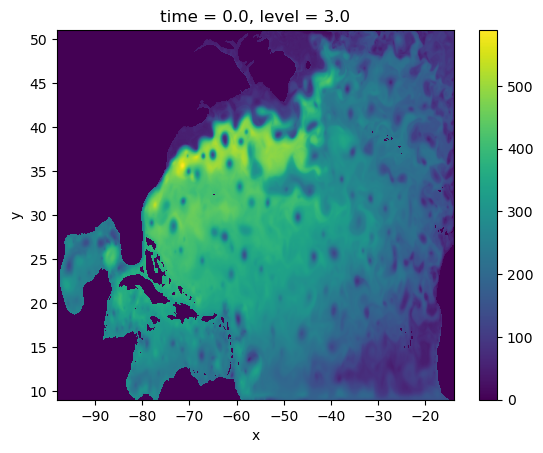

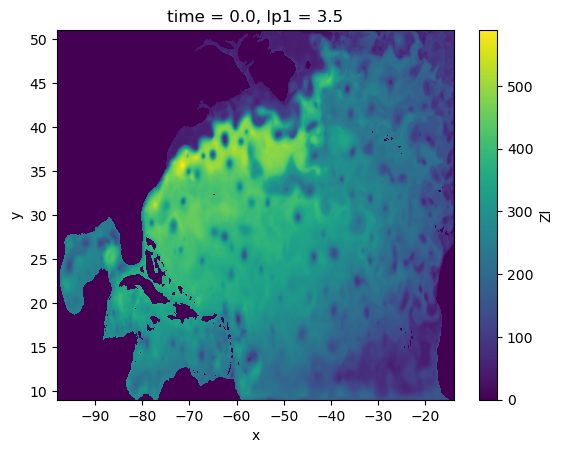

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 27.20 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


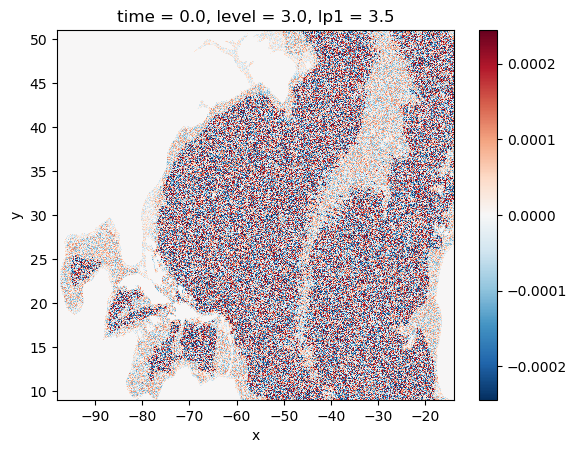

In [7]:
rho0 = 1e3
dr = np.array([.41,.31,.40,1.01])
gp = np.concatenate((g*dr/rho0, np.array([10.,])))
# gp = np.array([9.90e-3, 3.92e-3 , 3.04e-3, 4.02e-3])[::-1]
print(gp)

H = xr.open_zarr(op.join(ddir,"SW/48/bathy.zarr")).H
eta = -ds2.h.cumsum("level") + H

eta.isel(time=0,level=-2).plot(rasterized=True)
plt.show()
(-dsz.Zl.isel(time=0,lp1=-1)).plot(rasterized=True)
plt.show()
((eta.isel(time=0,level=-2)+dsz.Zl).isel(time=0,lp1=-1)).plot(rasterized=True)
plt.show()


In [115]:
# m = xr.DataArray(np.cumsum(eta.isel(level=slice(None,-1)).data[:,::-1]
#                            * gp[np.newaxis,::-1,np.newaxis,np.newaxis], 
#                            axis=1)[:,::-1],
#                  dims=["time","li","y","x"],
#                  coords={"time":ds2.time.data, 
#                          "li":ds2.lp1.isel(lp1=slice(1,-1)).data,
#                          "y":ds2.y.data, "x":ds2.x.data}
#                 )
# Zs = xr.concat([dsz.Zl, 
#                 xr.DataArray(ssh.data[:,np.newaxis,:,:],
#                              dims=["time","lp1","y","x"],
#                              coords={"time":ssh.time.data,
#                                      "lp1":np.array([4.5,]),
#                                      "y":ssh.y.data, "x":ssh.x.data})
#                ], "lp1").sortby("lp1")
m = xr.DataArray(np.cumsum(Zp1.isel(lp1=slice(1,None)).data[:,::-1]
                           * gp[np.newaxis,::-1,np.newaxis,np.newaxis], 
                           axis=1)[:,::-1],
                 dims=["time","level","y","x"],
                 coords={"time":ds2.time.data, 
                         "level":ds2.level.isel(level=slice(None,None)).data,
                         "y":ds2.y.data, "x":ds2.x.data}
                )

# phi = g * np.abs(dsz.Z)
# phil = g * np.abs(dsz.Zl)

# m = (phi + grid.interp(ds2.b,"Z",boundary="extend"
#                       )*dsz.Z
#     )
# ml = (phil + ds2.b*dsz.Zl)
print(m)
m.chunk({"time":4,"level":1,"y":128,"x":256}
       ).to_dataset(name="m").to_zarr(op.join(ddir,"SW/48/Montgomery.zarr"), 
                                      mode="w")

<xarray.DataArray 'getitem-0a20a207202fab0522d8bd03fd11f57b' (time: 630,
                                                              level: 5,
                                                              y: 2048, x: 4096)> Size: 211GB
dask.array<getitem, shape=(630, 5, 2048, 4096), dtype=float64, chunksize=(4, 4, 128, 256), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 53.28 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


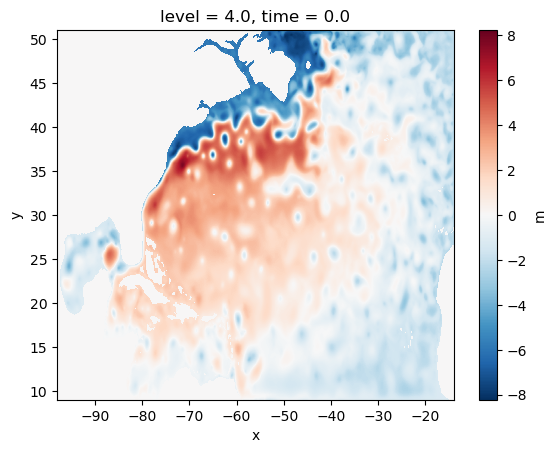

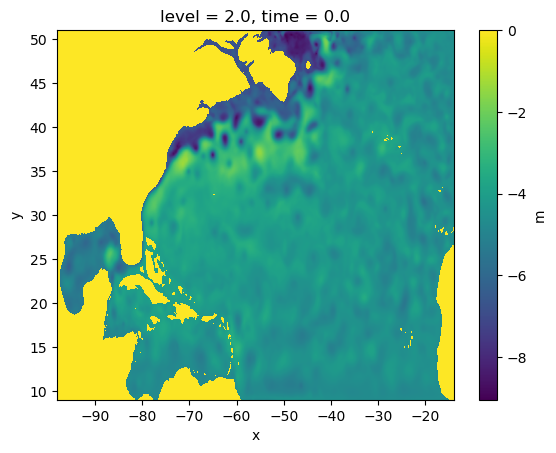

In [8]:
dsm = xr.open_zarr(op.join(ddir,"SW/48/Montgomery.zarr"))
dsm.m.isel(time=0,level=-1).plot(rasterized=True)
plt.show()
dsm.m.isel(time=0,level=-3).plot(rasterized=True)
plt.show()

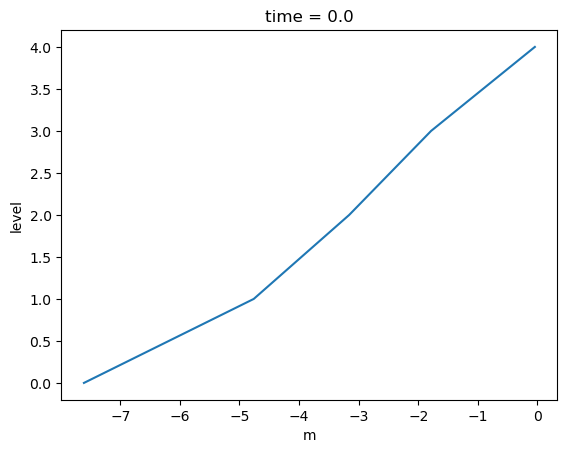

In [117]:
dsm.m.isel(time=0).mean(["y","x"]).plot(y="level")

$$\frac{m_1-m_2}{b_1 - b_2} = -\zeta_{1.5}\;\;\; \therefore b_1 = b_2 - \frac{m_1 - m_2}{\zeta_{1.5}}$$
$$b_1 - b_2 = g'_{1.5}$$

<xarray.DataArray (level: 5)> Size: 40B
array([-0.022883, -0.018865, -0.015337, -0.011858, -0.00196 ])
Coordinates:
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0


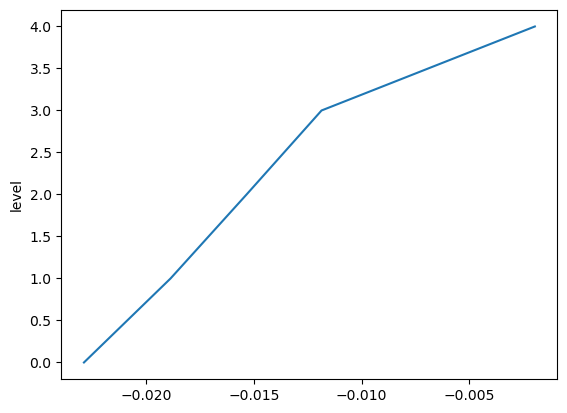

In [11]:
_b = grid.interp(ds2.bp1,"Z",padding="extend"
                ).isel(level=slice(1,-1))
# tmp = (b.isel(level=-2).data
#        - (grid.diff(dsm.m.chunk({"level":-1}),
#                     "Z",padding="extend"
#                    ).isel(lp1=-2)
#           / dsz.Zl.isel(lp1=-1)
#          ).mean(["time","y","x"],skipna=True).data
#       ).compute()
b = xr.concat([_b.copy(), 
               # xr.DataArray(np.array([tmp,]), dims=["level"],
               #              coords={"level":np.array([ds2.level[-1].values,])}
               #             )
               xr.DataArray(np.array([_b.isel(level=-1).data+gp[-2]]), 
                            dims=["level"],
                            coords={"level":np.array([ds2.level[-1].values,])}
                           )
              ], "level"
             ).sortby("level")
b = xr.concat([xr.DataArray(np.array([_b.isel(level=0).data-gp[0]]), 
                            dims=["level"],
                            coords={"level":np.array([ds2.level[0].values,])}
                           ),
               b], "level"
             ).sortby("level")
print(b)
b.plot(y="level")
plt.show()

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 36.26 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


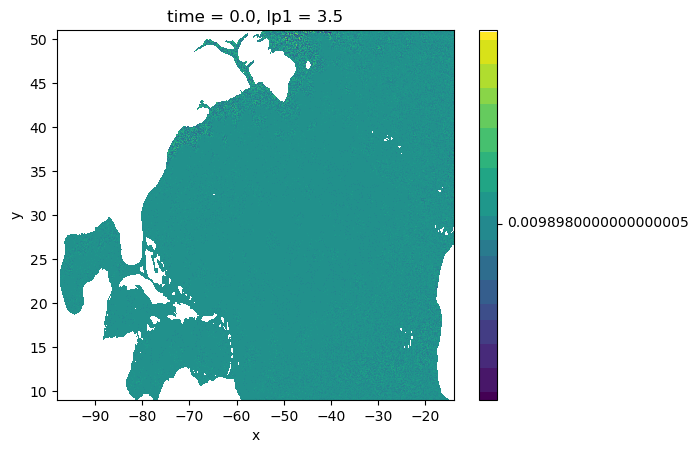

In [48]:
(-grid.diff(dsm.m.chunk({"level":-1}),"Z",padding="extend"
           ).isel(lp1=-2) / dsz.Zl.isel(lp1=-1)
).isel(time=0).plot(rasterized=True)

$$\zeta + m_\tilde{b} = 0$$

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 29.70 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


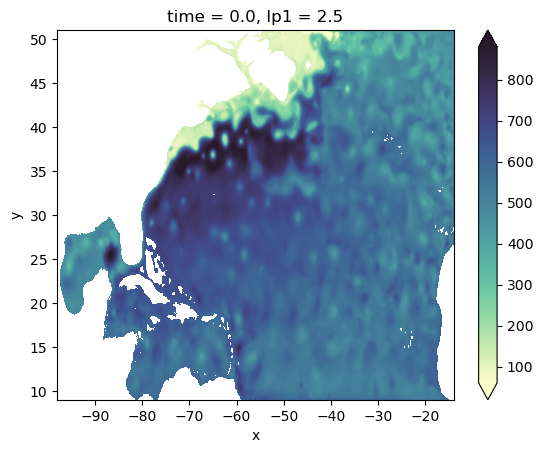

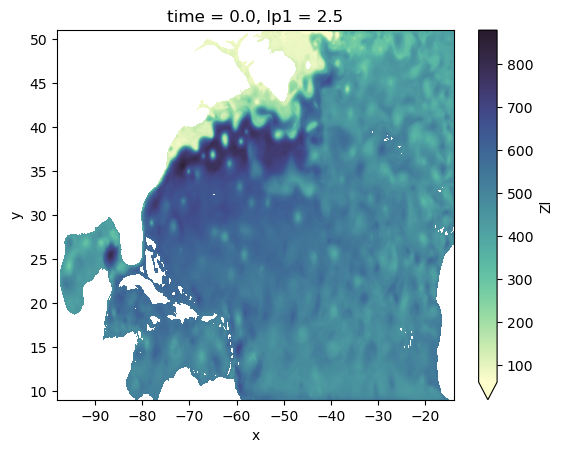

In [12]:
m_b = (grid.diff(dsm.m.chunk({"level":-1}),"Z",padding="extend")
       / grid.diff(b.chunk({"level":-1}),"Z",padding="extend")
      )
m_b.where(m_b>0.).isel(time=0,lp1=-3).plot(cmap=cmocean.cm.deep, 
                                           rasterized=True, vmax=880, vmin=60)
plt.show()
(-(dsz.Zl.where(dsz.Zl<0.))).isel(time=0, lp1=-2).plot(cmap=cmocean.cm.deep, 
                                                       rasterized=True, 
                                                       vmax=880, vmin=60)
# (-(dsz.Z.where(dsz.Z<0.))).isel(time=0,level=-2).plot(cmap=cmocean.cm.deep, 
#                                                       rasterized=True)
plt.show()

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 31.59 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


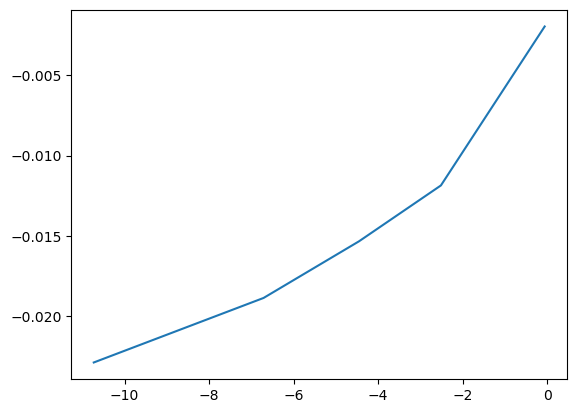

In [121]:
fig, ax = plt.subplots()
ax.plot(m.where(m!=0.).isel(time=0).mean(["y","x"]), 
        b)

$$fv = m_\tilde{x};\ fu = -m_\tilde{y}$$

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 64.04 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


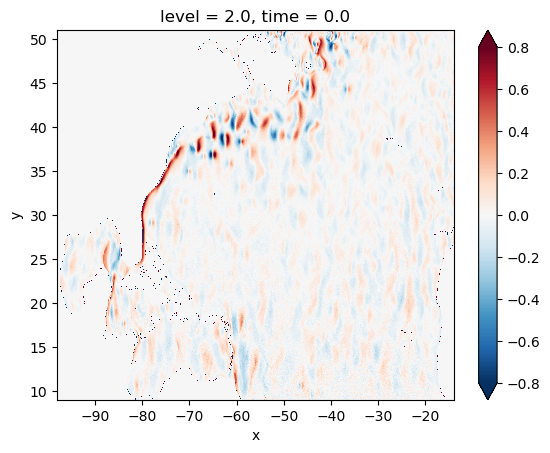

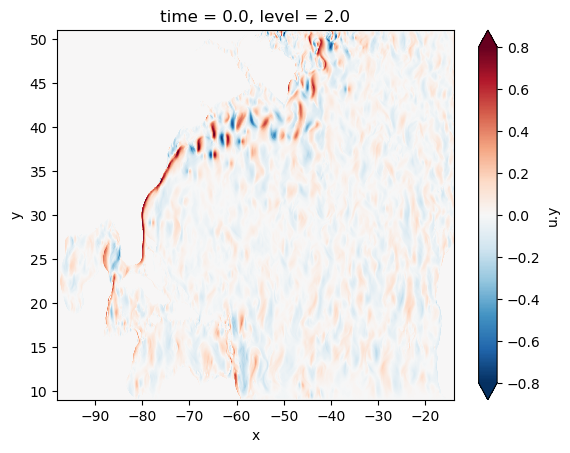

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 64.02 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


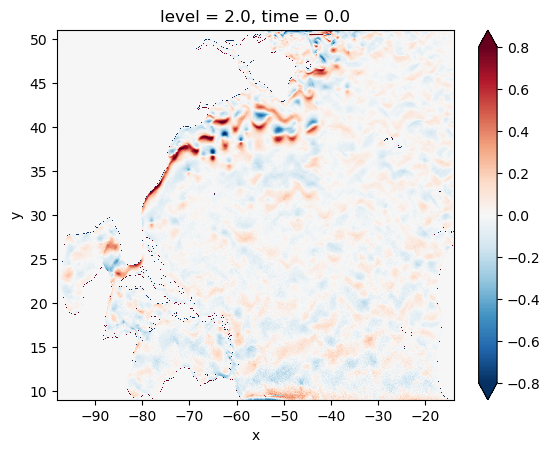

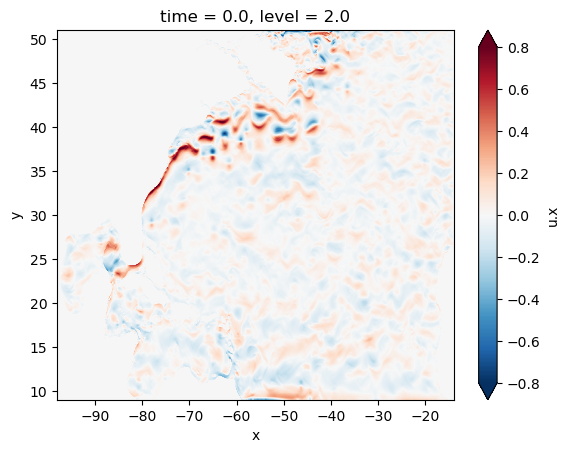

In [123]:
cori = gsw.f(ds.y)
(grid.interp(grid.diff(dsm.m.isel(time=0,level=-3).chunk({"x":-1}),"X",padding="extend")
             / xxG,"X",padding="extend") 
 / cori).plot(vmax=8e-1, rasterized=True)
plt.show()
(ds["u.y"]).isel(time=0,level=-3).plot(vmax=8e-1, rasterized=True)
plt.show()
(grid.interp(-grid.diff(dsm.m.isel(time=0,level=-3).chunk({"y":-1}),"Y",padding="extend")
             / yyG,"Y",padding="extend") 
 / cori).plot(vmax=8e-1, rasterized=True)
plt.show()
cori = gsw.f(ds.y)
(ds["u.x"]).isel(time=0,level=-3).plot(vmax=8e-1, rasterized=True)
plt.show()

In [9]:
dspp = xr.open_zarr(op.join(ddir,"SW/48/TWA/Upp.zarr"))
dszp = dsz - dsz.mean("time")
mp = dsm.m - dsm.m.mean("time")
dspp, mp

(<xarray.Dataset> Size: 169GB
 Dimensions:  (time: 630, level: 4, y: 2048, x: 4096)
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
 Data variables:
     upp      (time, level, y, x) float32 85GB dask.array<chunksize=(10, 1, 256, 512), meta=np.ndarray>
     vpp      (time, level, y, x) float32 85GB dask.array<chunksize=(10, 1, 256, 512), meta=np.ndarray>,
 <xarray.DataArray 'm' (time: 630, level: 5, y: 2048, x: 4096)> Size: 211GB
 dask.array<sub, shape=(630, 5, 2048, 4096), dtype=float64, chunksize=(4, 1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.07

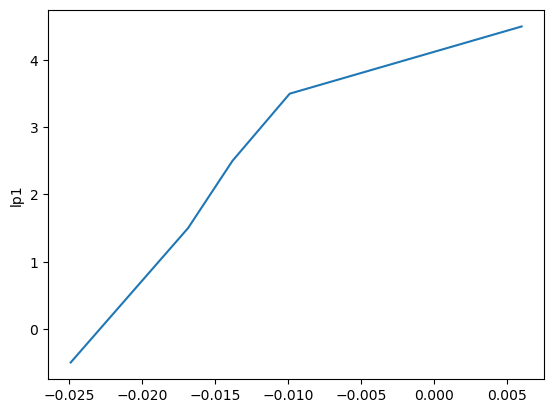

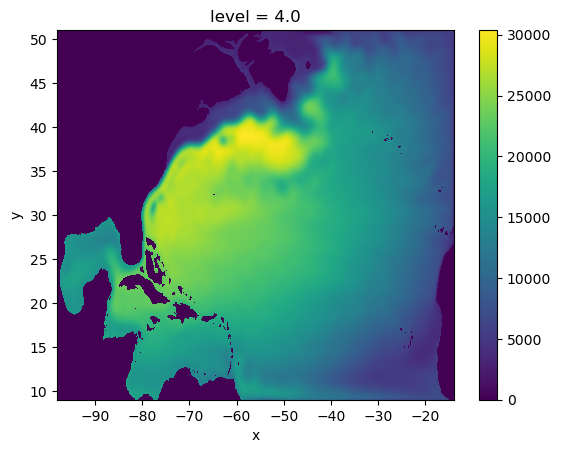

(<xarray.DataArray (time: 630, level: 5, y: 2048, x: 4096)> Size: 211GB
 dask.array<truediv, shape=(630, 5, 2048, 4096), dtype=float64, chunksize=(4, 1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01,
 <xarray.DataArray (level: 4, y: 2048, x: 4096)> Size: 268MB
 dask.array<truediv, shape=(4, 2048, 4096), dtype=float64, chunksize=(1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01)

In [12]:
dsb = xr.open_zarr(op.join(ddir,"SW/48/mean/UVh.zarr")
                  ).chunk({"level":1,"y":128,"x":256}
                         )

_bp1 = ds2.bp1.isel(lp1=slice(1,-1))
bp1 = xr.concat([_bp1.copy(), 
                 xr.DataArray(np.array([_bp1.isel(lp1=-1)
                                        + 2*(b.isel(level=-1)-_bp1.isel(lp1=-1)
                                            ).data,
                                       ]),
                              dims=["lp1"], 
                              coords={"lp1":np.array([ds2.lp1[-1].values,]),})
                ], "lp1").sortby("lp1")
bp1 = xr.concat([xr.DataArray(np.array([_bp1.isel(lp1=0)
                                        + 2*(b.isel(level=0)-_bp1.isel(lp1=0)
                                            ).data,
                                       ]),
                              dims=["lp1"], 
                              coords={"lp1":np.array([ds2.lp1[0].values,]),}), 
                 bp1
                ], "lp1").sortby("lp1")
bp1.plot(y="lp1")
plt.show()

# sig = (ds2.h
#        / grid.diff(ds2.bp1,"Z",padding="extend")
#       )
# sigb = (dsb.hbar / grid.diff(ds2.bp1,"Z",padding="extend"))
sig = (ds2.h
       / grid.diff(bp1.chunk({"lp1":-1}),"Z",padding="extend")
      )
sigb = (dsb.hbar 
        / grid.diff(bp1.chunk({"lp1":-1}),
                    "Z",padding="extend"))
sigb.isel(level=-1).plot(rasterized=True)
plt.show()
sig, sigb

In [12]:
E00 = (sig * dspp.upp**2).mean("time")
Ediag = .5*(dszp.Z**2).mean("time")
Ecros = (sig * dspp.vpp * dspp.upp).mean("time")
E20 = (dszp.Z.isel(level=slice(None,None)) # sign convention of zeta
       * grid.interp(grid.diff(mp.chunk({"x":-1}),"X",padding="extend"
                              ) / xxG,
                     "X",padding="extend")
      ).mean("time")
E11 = (sig * dspp.vpp**2).mean("time")
E21 = (dszp.Z.isel(level=slice(None,None)) # sign convention of zeta
       * grid.interp(grid.diff(mp.chunk({"y":-1}),"Y",padding="extend"
                              ) / yyG,
                     "Y",padding="extend")
      ).mean("time")

dsave = E00.to_dataset(name="E00")
dsave["Ediag"] = Ediag
dsave["Ecros"] = Ecros
dsave["E20"] = E20
dsave["E11"] = E11
dsave["E21"] = E21
print(dsave)

dsave.to_zarr(op.join(ddir,"SW/48/TWA/E-P.zarr"), mode="w")
dsave.close()

<xarray.Dataset> Size: 1GB
Dimensions:  (level: 4, y: 2048, x: 4096)
Coordinates:
  * level    (level) float32 16B 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    E00      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    Ediag    (level, y, x) float32 134MB dask.array<chunksize=(2, 128, 256), meta=np.ndarray>
    Ecros    (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    E20      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    E11      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    E21      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 382.27 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [13]:
dsep = xr.open_zarr(op.join(ddir,"SW/48/TWA/E-P.zarr"))

dsep.coords["yG"] = ("yG",.5*(ds2.y.data[1:]+ds2.y.data[:-1]))
dsep.coords["xG"] = ("xG",.5*(ds2.x.data[1:]+ds2.x.data[:-1]))
dsep.coords["li"] = ("li",ds2.lp1.isel(lp1=slice(1,None)).data)
# dsep.coords["b"] = ("li",ds2.b.isel(lp1=slice(1,None)).data)

gridp = Grid(dsep, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
             autoparse_metadata=False,
             coords={"X": {"center": "x",     "inner": "xG"},
                     "Y": {"center": "y",     "inner": "yG"},
                     "Z": {"center": "level", "outer": "li"}
                    })
dsep, gridp

(<xarray.Dataset> Size: 1GB
 Dimensions:  (level: 4, y: 2048, x: 4096, yG: 2047, xG: 4095, li: 5)
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * yG       (yG) float32 8kB 9.021 9.041 9.062 9.082 ... 50.94 50.96 50.98
   * xG       (xG) float32 16kB -97.98 -97.96 -97.94 ... -14.06 -14.04 -14.02
   * li       (li) float64 40B 0.5 1.5 2.5 3.5 4.5
 Data variables:
     E00      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     E11      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     E20      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     E21      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     Ecros    (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256),

In [14]:
Ju0_x = gridp.interp(gridp.diff(dsep.E00.chunk({"x":-1}), 
                                "X", padding="extend")
                     / xxG, "X", padding="extend"
                    )
Ju0 = -((Ju0_x 
         + gridp.interp(gridp.diff(dsep.Ecros.chunk({"y":-1}), 
                                   "Y", padding="extend")
                        / yyG, "Y", padding="extend"
                       )
        ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Ju1 = -(gridp.interp(gridp.diff(dsep.Ediag.chunk({"x":-1}), 
                                "X", padding="extend")
                     / xxG, "X", padding="extend"
                    ) * sigb**-1).isel(level=-2).fillna(0.).compute()
# Ju2 = -((gridp.interp(gridp.diff(dsep.E20.chunk({"level":-1}), "Z", padding="extend"), 
#                       "Z", padding="extend")
#          / gridp.diff(dsep.b, "Z", padding="extend")
#         ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Ju2 = -(gridp.interp(gridp.diff(dsep.E20.chunk({"level":-1}), 
                                "Z", padding="extend")
                     / gridp.diff(b.isel(level=slice(1,None)).chunk({"level":-1}), 
                                  "Z", padding="extend"
                                 ), 
                     "Z", padding="extend")
        * sigb**-1).isel(level=-2).fillna(0.).compute()

Jv0_x = gridp.interp(gridp.diff(dsep.Ecros.chunk({"x":-1}), 
                                "X", padding="extend")
                     / xxG, "X", padding="extend"
                    )
Jv0 = -((Jv0_x 
         + gridp.interp(gridp.diff(dsep.E11.chunk({"y":-1}), 
                                   "Y", padding="extend")
                        / yyG, "Y", padding="extend"
                       )
        ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Jv1 = -(gridp.interp(gridp.diff(dsep.Ediag.chunk({"y":-1}), 
                                "Y", padding="extend")
                     / yyG, "Y", padding="extend"
                    ) * sigb**-1).isel(level=-2).fillna(0.).compute()
# Jv2 = -((gridp.interp(gridp.diff(dsep.E21.chunk({"level":-1}), "Z", padding="extend"), 
#                      "Z", padding="extend") 
#          / gridp.diff(dsep.b, "Z", padding="extend")
#         ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Jv2 = -(gridp.interp(gridp.diff(dsep.E21.chunk({"level":-1}), 
                                "Z", padding="extend")
                     / gridp.diff(b.isel(level=slice(1,None)).chunk({"level":-1}), 
                                  "Z", padding="extend"
                                 ), 
                     "Z", padding="extend") 
        * sigb**-1).isel(level=-2).fillna(0.).compute()

Ju2, Jv2

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/dask/array/core.py:5200: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 128.44 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 64.26 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.

(<xarray.DataArray (y: 2048, x: 4096)> Size: 67MB
 array([[-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        ...,
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
          1.33280669e-09,  2.80975045e-09,  2.94455624e-09],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
          1.31960851e-09,  1.37848076e-09,  6.96839472e-10],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
          5.06573070e-10,  8.15093627e-10,  4.07539193e-10]],
       shape=(2048, 4096))
 Coordinates:
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -1

In [15]:
Fu = Ju0 + Ju1 + Ju2
Fv = Jv0 + Jv1 + Jv2
Fu, Fv

(<xarray.DataArray (y: 2048, x: 4096)> Size: 67MB
 array([[-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        ...,
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
          1.93515744e-08,  1.45277926e-08,  6.26946802e-09],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
          1.50172946e-08,  1.11847425e-08,  4.93803594e-09],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
          1.14066031e-08,  8.96894427e-09,  4.93206475e-09]],
       shape=(2048, 4096))
 Coordinates:
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -1

In [17]:
sshb = ssh.mean("time").compute()

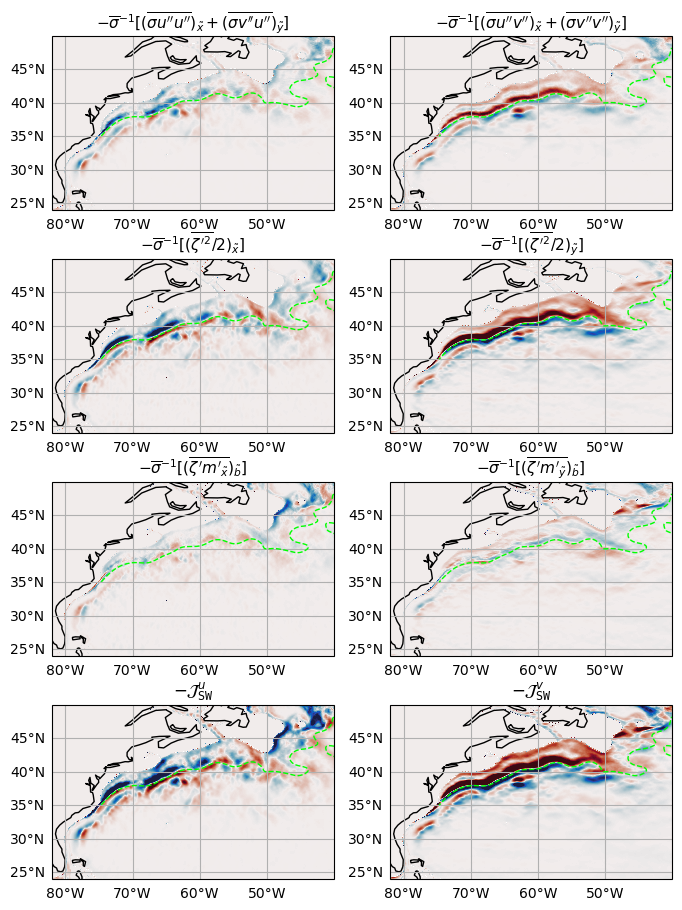

In [19]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

fig = plt.figure(figsize=(8,11.1))
ax1 = fig.add_subplot(4, 2, 1, projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(4, 2, 3, projection=ccrs.PlateCarree())
ax3 = fig.add_subplot(4, 2, 5, projection=ccrs.PlateCarree())
ax4 = fig.add_subplot(4, 2, 7, projection=ccrs.PlateCarree())
ax5 = fig.add_subplot(4, 2, 2, projection=ccrs.PlateCarree())
ax6 = fig.add_subplot(4, 2, 4, projection=ccrs.PlateCarree())
ax7 = fig.add_subplot(4, 2, 6, projection=ccrs.PlateCarree())
ax8 = fig.add_subplot(4, 2, 8, projection=ccrs.PlateCarree())
ax1.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax2.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax3.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax4.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax5.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax6.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax7.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax8.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax1.coastlines(resolution='110m')
ax2.coastlines(resolution='110m')
ax3.coastlines(resolution='110m')
ax4.coastlines(resolution='110m')
ax5.coastlines(resolution='110m')
ax6.coastlines(resolution='110m')
ax7.coastlines(resolution='110m')
ax8.coastlines(resolution='110m')
gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl1.right_labels = False
gl2 = ax2.gridlines(draw_labels=True)
gl2.top_labels = False
gl2.right_labels = False
gl3 = ax3.gridlines(draw_labels=True)
gl3.top_labels = False
gl3.right_labels = False
gl4 = ax4.gridlines(draw_labels=True)
gl4.top_labels = False
gl4.right_labels = False
gl5 = ax5.gridlines(draw_labels=True)
gl5.top_labels = False
gl5.right_labels = False
gl6 = ax6.gridlines(draw_labels=True)
gl6.top_labels = False
gl6.right_labels = False
gl7 = ax7.gridlines(draw_labels=True)
gl7.top_labels = False
gl7.right_labels = False
gl8 = ax8.gridlines(draw_labels=True)
gl8.top_labels = False
gl8.right_labels = False

ax1.pcolormesh(dsb.x, dsb.y, Ju0, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )
ax2.pcolormesh(dsb.x, dsb.y, Ju1, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )
ax3.pcolormesh(dsb.x, dsb.y, Ju2, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )
ax4.pcolormesh(dsb.x, dsb.y, Fu, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )

ax5.pcolormesh(dsb.x, dsb.y, Jv0, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )
im = ax6.pcolormesh(dsb.x, dsb.y, Jv1, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )
ax7.pcolormesh(dsb.x, dsb.y, Jv2, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )
ax8.pcolormesh(dsb.x, dsb.y, Fv, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )

ax1.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax2.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax3.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax4.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax5.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax6.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax7.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax8.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)

ax1.set_rasterized(True)
ax2.set_rasterized(True)
ax3.set_rasterized(True)
ax4.set_rasterized(True)
ax5.set_rasterized(True)
ax6.set_rasterized(True)
ax7.set_rasterized(True)
ax8.set_rasterized(True)

# ax4.set_xlabel(r"Longitude")
# ax1.set_ylabel(r"Latitude")
# ax2.set_ylabel(r"Latitude")
# ax3.set_ylabel(r"Latitude")
# ax4.set_ylabel(r"Latitude")
ax1.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\sigma u''u''})_\tilde{x} + (\overline{\sigma v''u''})_\tilde{y}]$", 
              fontsize=11)
ax2.set_title(r"$-\overline{\sigma}^{-1}[(\overline{{\zeta'}^2}/2)_\tilde{x}]$", fontsize=11)
ax3.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\zeta' m'_\tilde{x}})_\tilde{b}]$", 
              fontsize=11)
ax4.set_title(r"$-\mathcal{J}^u_{\tt SW}$", fontsize=12)

ax5.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\sigma u''v''})_\tilde{x} + (\overline{\sigma v''v''})_\tilde{y}]$", 
              fontsize=11)
ax6.set_title(r"$-\overline{\sigma}^{-1}[(\overline{{\zeta'}^2}/2)_\tilde{y}]$", fontsize=11)
ax7.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\zeta' m'_\tilde{y}})_\tilde{b}]$", 
              fontsize=11)
ax8.set_title(r"$-\mathcal{J}^v_{\tt SW}$", fontsize=12)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/E-P_SW.pdf"), dpi=200)

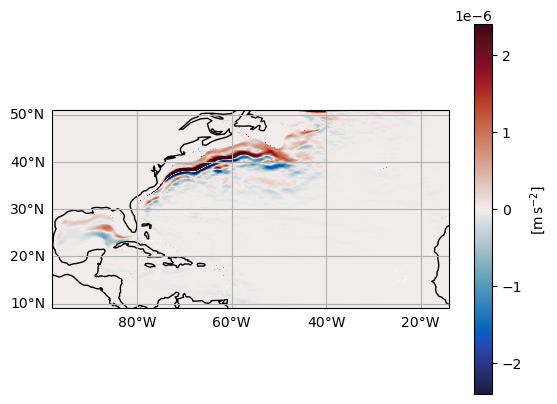

In [30]:
fig = plt.figure()
ax6 = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax6.set_extent([dsb.x.min(), dsb.x.max(), dsb.y.min(), dsb.y.max()], 
              crs=ccrs.PlateCarree())
ax6.coastlines(resolution='110m')
gl6 = ax6.gridlines(draw_labels=True)
gl6.top_labels = False
gl6.right_labels = False

im = ax6.pcolormesh(dsb.x, dsb.y, Jv1, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               rasterized=True)

cb = fig.colorbar(im, ax=ax6)
cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/E-P_SW_cbar.pdf"))

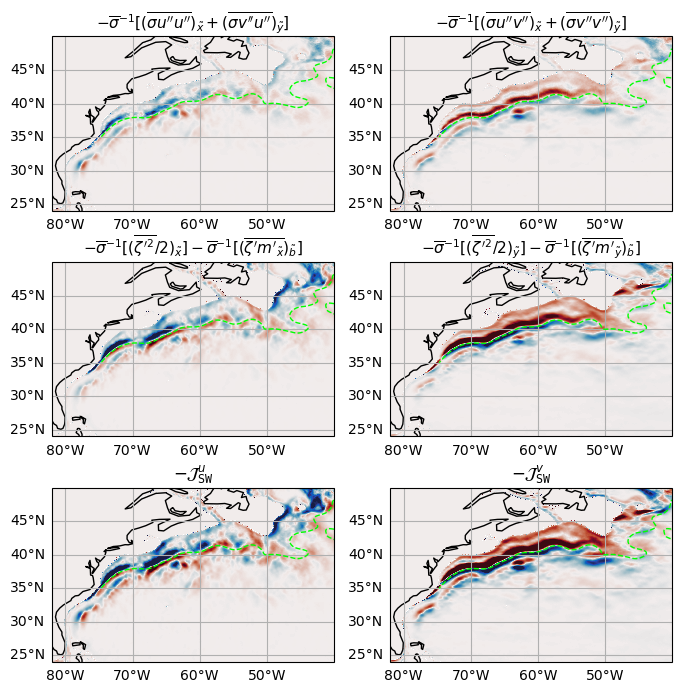

In [22]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

fig = plt.figure(figsize=(8,8.3))
ax1 = fig.add_subplot(3, 2, 1, projection=ccrs.PlateCarree())
# ax2 = fig.add_subplot(4, 2, 3, projection=ccrs.PlateCarree())
ax3 = fig.add_subplot(3, 2, 3, projection=ccrs.PlateCarree())
ax4 = fig.add_subplot(3, 2, 5, projection=ccrs.PlateCarree())
ax5 = fig.add_subplot(3, 2, 2, projection=ccrs.PlateCarree())
# ax6 = fig.add_subplot(4, 2, 4, projection=ccrs.PlateCarree())
ax7 = fig.add_subplot(3, 2, 4, projection=ccrs.PlateCarree())
ax8 = fig.add_subplot(3, 2, 6, projection=ccrs.PlateCarree())
ax1.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
# ax2.set_extent([xmin, xmax, ymin, ymax], 
#               crs=ccrs.PlateCarree())
ax3.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax4.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax5.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
# ax6.set_extent([xmin, xmax, ymin, ymax], 
#               crs=ccrs.PlateCarree())
ax7.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax8.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax1.coastlines(resolution='110m')
# ax2.coastlines(resolution='110m')
ax3.coastlines(resolution='110m')
ax4.coastlines(resolution='110m')
ax5.coastlines(resolution='110m')
# ax6.coastlines(resolution='110m')
ax7.coastlines(resolution='110m')
ax8.coastlines(resolution='110m')
gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl1.right_labels = False
# gl2 = ax2.gridlines(draw_labels=True)
# gl2.top_labels = False
# gl2.right_labels = False
gl3 = ax3.gridlines(draw_labels=True)
gl3.top_labels = False
gl3.right_labels = False
gl4 = ax4.gridlines(draw_labels=True)
gl4.top_labels = False
gl4.right_labels = False
gl5 = ax5.gridlines(draw_labels=True)
gl5.top_labels = False
gl5.right_labels = False
# gl6 = ax6.gridlines(draw_labels=True)
# gl6.top_labels = False
# gl6.right_labels = False
gl7 = ax7.gridlines(draw_labels=True)
gl7.top_labels = False
gl7.right_labels = False
gl8 = ax8.gridlines(draw_labels=True)
gl8.top_labels = False
gl8.right_labels = False

ax1.pcolormesh(dsb.x, dsb.y, Ju0, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )
# ax2.pcolormesh(dsb.x, dsb.y, Fu1, 
#                cmap=cmocean.cm.balance,
#                # cmap="RdBu_r",
#                vmin=-2.4e-6, vmax=2.4e-6,
#                rasterized=True)
ax3.pcolormesh(dsb.x, dsb.y, Ju1+Ju2, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )
ax4.pcolormesh(dsb.x, dsb.y, Fu, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )

ax5.pcolormesh(dsb.x, dsb.y, Jv0, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )
# im = ax6.pcolormesh(dsb.x, dsb.y, Fv1, 
#                cmap=cmocean.cm.balance,
#                # cmap="RdBu_r",
#                vmin=-2.4e-6, vmax=2.4e-6,
#                rasterized=True)
ax7.pcolormesh(dsb.x, dsb.y, Jv1+Jv2, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )
ax8.pcolormesh(dsb.x, dsb.y, Fv, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
              )

ax1.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax3.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax4.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax5.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax7.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax8.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)

ax1.set_rasterized(True)
ax3.set_rasterized(True)
ax4.set_rasterized(True)
ax5.set_rasterized(True)
ax7.set_rasterized(True)
ax8.set_rasterized(True)

# ax4.set_xlabel(r"Longitude")
# ax1.set_ylabel(r"Latitude")
# ax2.set_ylabel(r"Latitude")
# ax3.set_ylabel(r"Latitude")
# ax4.set_ylabel(r"Latitude")
ax1.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\sigma u''u''})_\tilde{x} + (\overline{\sigma v''u''})_\tilde{y}]$", 
              fontsize=11)
# ax2.set_title(r"$-\overline{\sigma}^{-1}[(\overline{{\zeta'}^2}/2)_\tilde{x}]$", fontsize=11)
ax3.set_title(r"$-\overline{\sigma}^{-1}[(\overline{{\zeta'}^2}/2)_\tilde{x}]-\overline{\sigma}^{-1}[(\overline{\zeta' m'_\tilde{x}})_\tilde{b}]$", 
              fontsize=11)
ax4.set_title(r"$-\mathcal{J}^u_{\tt SW}$", fontsize=12)

ax5.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\sigma u''v''})_\tilde{x} + (\overline{\sigma v''v''})_\tilde{y}]$", 
              fontsize=11)
# ax6.set_title(r"$-\overline{\sigma}^{-1}[(\overline{{\zeta'}^2}/2)_\tilde{y}]$", fontsize=11)
ax7.set_title(r"$-\overline{\sigma}^{-1}[(\overline{{\zeta'}^2}/2)_\tilde{y}]-\overline{\sigma}^{-1}[(\overline{\zeta' m'_\tilde{y}})_\tilde{b}]$", 
              fontsize=11)
ax8.set_title(r"$-\mathcal{J}^v_{\tt SW}$", fontsize=12)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/E-P_SW_added.pdf"), dpi=200)

In [15]:
Fu0_x = gridp.interp(gridp.diff(dsep.E00.chunk({"x":-1}), "X", boundary="extend")
                     / xxG, "X", boundary="extend"
                    )
Fu0 = -((Fu0_x 
         + gridp.interp(gridp.diff(dsep.Ediag.chunk({"x":-1}), "X", boundary="extend")
                     / xxG, "X", boundary="extend"
                    )
        ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Fu1 = -(gridp.interp(gridp.diff(dsep.Ecros.chunk({"y":-1}), "Y", boundary="extend")
                     / yyG, "Y", boundary="extend"
                    ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Fu2 = -((gridp.diff(dsep.E20, "Z", boundary="extend"
                   ) / grid.diff(ds2.b, "Z", boundary="extend")
        ) * sigb**-1).isel(level=-2).fillna(0.).compute()
####################
Fv0 = -(gridp.interp(gridp.diff(dsep.Ecros.chunk({"x":-1}), "X", boundary="extend")
                     / xxG, "X", boundary="extend"
                    ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Fv1_y = gridp.interp(gridp.diff(dsep.Ediag.chunk({"y":-1}), "Y", boundary="extend")
                     / yyG, "Y", boundary="extend"
                    ) 
Fv1 = -((Fv1_y 
         + gridp.interp(gridp.diff(dsep.E11.chunk({"y":-1}), "Y", boundary="extend")
                        / yyG, "Y", boundary="extend"
                       )
        ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Fv2 = -((gridp.diff(dsep.E21, "Z", boundary="extend"
                   ) / grid.diff(ds2.b, "Z", boundary="extend")
        ) * sigb**-1).isel(level=-2).fillna(0.).compute()

Fu2, Fv2

ValueError: Argument 'boundary' has been renamed to 'padding'. Please use 'padding' instead.

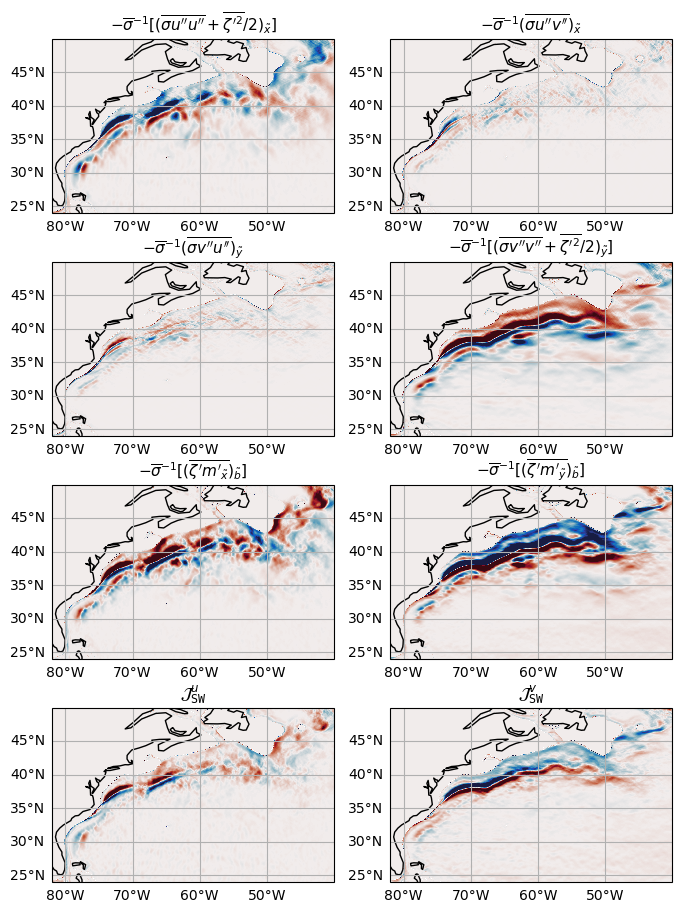

In [37]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

fig = plt.figure(figsize=(8,11.1))
ax1 = fig.add_subplot(4, 2, 1, projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(4, 2, 3, projection=ccrs.PlateCarree())
ax3 = fig.add_subplot(4, 2, 5, projection=ccrs.PlateCarree())
ax4 = fig.add_subplot(4, 2, 7, projection=ccrs.PlateCarree())
ax5 = fig.add_subplot(4, 2, 2, projection=ccrs.PlateCarree())
ax6 = fig.add_subplot(4, 2, 4, projection=ccrs.PlateCarree())
ax7 = fig.add_subplot(4, 2, 6, projection=ccrs.PlateCarree())
ax8 = fig.add_subplot(4, 2, 8, projection=ccrs.PlateCarree())
ax1.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax2.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax3.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax4.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax5.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax6.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax7.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax8.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax1.coastlines(resolution='110m')
ax2.coastlines(resolution='110m')
ax3.coastlines(resolution='110m')
ax4.coastlines(resolution='110m')
ax5.coastlines(resolution='110m')
ax6.coastlines(resolution='110m')
ax7.coastlines(resolution='110m')
ax8.coastlines(resolution='110m')
gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl1.right_labels = False
gl2 = ax2.gridlines(draw_labels=True)
gl2.top_labels = False
gl2.right_labels = False
gl3 = ax3.gridlines(draw_labels=True)
gl3.top_labels = False
gl3.right_labels = False
gl4 = ax4.gridlines(draw_labels=True)
gl4.top_labels = False
gl4.right_labels = False
gl5 = ax5.gridlines(draw_labels=True)
gl5.top_labels = False
gl5.right_labels = False
gl6 = ax6.gridlines(draw_labels=True)
gl6.top_labels = False
gl6.right_labels = False
gl7 = ax7.gridlines(draw_labels=True)
gl7.top_labels = False
gl7.right_labels = False
gl8 = ax8.gridlines(draw_labels=True)
gl8.top_labels = False
gl8.right_labels = False

ax1.pcolormesh(dsb.x, dsb.y, Fu0, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               rasterized=True)
ax2.pcolormesh(dsb.x, dsb.y, Fu1, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               rasterized=True)
ax3.pcolormesh(dsb.x, dsb.y, Fu2, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               rasterized=True)
ax4.pcolormesh(dsb.x, dsb.y, Fu, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               rasterized=True)

ax5.pcolormesh(dsb.x, dsb.y, Fv0, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               rasterized=True)
im = ax6.pcolormesh(dsb.x, dsb.y, Fv1, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               rasterized=True)
ax7.pcolormesh(dsb.x, dsb.y, Fv2, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               rasterized=True)
ax8.pcolormesh(dsb.x, dsb.y, Fv, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.4e-6, vmax=2.4e-6,
               rasterized=True)

# ax4.set_xlabel(r"Longitude")
# ax1.set_ylabel(r"Latitude")
# ax2.set_ylabel(r"Latitude")
# ax3.set_ylabel(r"Latitude")
# ax4.set_ylabel(r"Latitude")
ax1.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\sigma u''u''} + \overline{{\zeta'}^2}/2)_\tilde{x}]$", 
              fontsize=11)
ax2.set_title(r"$-\overline{\sigma}^{-1}(\overline{\sigma v''u''})_\tilde{y}$", fontsize=11)
ax3.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\zeta' m'_\tilde{x}})_\tilde{b}]$", 
              fontsize=11)
ax4.set_title(r"$\mathcal{J}^u_{\tt SW}$", fontsize=12)

ax5.set_title(r"$-\overline{\sigma}^{-1}(\overline{\sigma u''v''})_\tilde{x}$", 
              fontsize=11)
ax6.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\sigma v''v''} + \overline{{\zeta'}^2}/2)_\tilde{y}]$", fontsize=11)
ax7.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\zeta' m'_\tilde{y}})_\tilde{b}]$", 
              fontsize=11)
ax8.set_title(r"$\mathcal{J}^v_{\tt SW}$", fontsize=12)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/E-P_SW_xyz.pdf"), dpi=200)

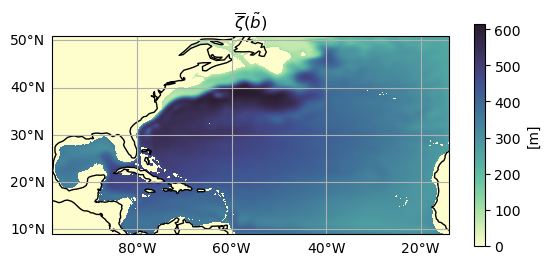

In [29]:
yy = np.arange(10,60,10)
xx = np.arange(-96.,-15,11.5)

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([dsb.x.min(), dsb.x.max(), dsb.y.min(), dsb.y.max()], 
              crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(dsz.x, dsz.y, 
                   np.abs(dsz.Z.isel(level=-2).mean("time")), 
                   cmap=cmocean.cm.deep,
                   rasterized=True)

# for yyy in yy:
#     ax.plot(xx, np.ones_like(xx)*yyy, "r--", alpha=.9)
# for xxx in xx:
#     ax.plot(np.ones_like(yy)*xxx, yy, "r--", alpha=.9)
# ax.set_aspect("equal")

# ax.set_xlabel(r"Longitude")
# ax.set_ylabel(r"Latitude")
ax.set_title(r"$\overline{\zeta}(\tilde{b})$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[m]")
plt.savefig(op.join(ddir,"Figs/Z_level-2.pdf"))

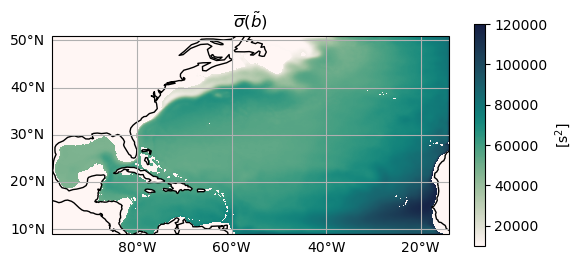

In [32]:
yy = np.arange(10,60,10)
xx = np.arange(-96.,-15,11.5)

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([dsb.x.min(), dsb.x.max(), dsb.y.min(), dsb.y.max()], 
              crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(dsz.x, dsz.y, sigb.isel(level=-2), 
                   cmap=cmocean.cm.tempo,
                   vmin=1e4, vmax=12e4,
                   rasterized=True)

# for yyy in yy:
#     ax.plot(xx, np.ones_like(xx)*yyy, "r--", alpha=.9)
# for xxx in xx:
#     ax.plot(np.ones_like(yy)*xxx, yy, "r--", alpha=.9)
# ax.set_aspect("equal")

# ax.set_xlabel(r"Longitude")
# ax.set_ylabel(r"Latitude")
ax.set_title(r"$\overline{\sigma}(\tilde{b})$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[s$^2$]")
plt.savefig(op.join(ddir,"Figs/sig_level-2.pdf"))